In [7]:
import qewton.equations as eq

X = eq.Variable("x", dim=2)
T = eq.Variable("t", dim=1)
U = eq.Variable("u", dim=1)
F = eq.Variable("f", dim=1)
a = eq.Variable("a", dim=1)

func_u = eq.FunctionSymbol(U, X*T)
func_a = eq.FunctionSymbol(a, T)
func_f = eq.FunctionSymbol(F, T)

Omega = eq.Domain('Omega', ambient=X)
I = eq.Domain('I', ambient=T)
dO = eq.Boundary(Omega)

lhs = eq.d(func_u, T) - eq.div(2.0*eq.grad(func_u, X), X)

inner_eq = eq.Eq(lhs, func_f).on(Omega*I)
bc_eq = eq.Eq(func_u, 0).on(dO*I)
initial_eq = eq.Eq(func_u, 0).on(Omega*eq.Slice(T, 0))

problem = eq.Problem((inner_eq, bc_eq, initial_eq), time=T)
print(problem)

constraints:
  1. ∂u/∂t − ∇_x·(2·∇_x u) = f on Omega × I
  2. u = 0 on ∂Omega × I
  3. u = 0 on Omega × {t = 0}
time: t


In [8]:
print(problem.overview())

coordinates:
  x  space, dim 2
  t  time
sets:
  I  domain in t
  Omega  domain in x
  Omega × I  product
  Omega × {t = 0}  product
  {t = 0}  slice of t
  ∂Omega  boundary of Omega
  ∂Omega × I  product
functions:
  f(t)  scalar
  u(x, t)  scalar
constraints: 3


In [9]:
forward_task = problem.task(
    unknown=(func_u,),
    fixed=(func_f,),
    varying=(Omega, )
)
print(eq.signatures(forward_task))

f : t → ℝ  [fixed]  on Omega × I
u : x × t × p_Omega → ℝ  [unknown; inherits p_Omega]  on Omega × I, ∂Omega × I


In [10]:
ctx = eq.AnalysisContext(forward_task)
print(ctx.report())

Task
  unknown: u
  fixed: f
  varying sets: Omega
  batch axis of Omega: p_Omega
Signatures
  f : t → ℝ  [fixed]  on Omega × I
  u : x × t × p_Omega → ℝ  [unknown; inherits p_Omega]  on Omega × I, ∂Omega × I
Normalized
  constraints:
    1. ∂u/∂t − ∇_x·(2·∇_x u) − f = 0 on Omega × I
    2. u = 0 on ∂Omega × I
    3. u = 0 on Omega × {t = 0}
  time: t
Batching
  p_Omega (Omega): geometry; reaches u
  instances are independent: parallel over the batch
Classification
  equations:
    ∂u/∂t − ∇_x·(2·∇_x u) − f = 0 on Omega × I: parabolic  (highest time order 1, highest space order 2)
  blocks:
    u: parabolic  (dominant type of equations 1)
  conditions:
    u = 0 on ∂Omega × I: Dirichlet  (the unknown terms contain Dirichlet data)
    u = 0 on Omega × {t = 0}: initial  (it fixes the unknown at the start time)
  counts:
    ∂Omega: (1, 1)  (1 given, 1 needed)
    u, order 0: (1, 1)  (1 given, 1 needed)
  function spaces:
    u: H1  (derivatives left after moving half the equation order t

<Axes: >

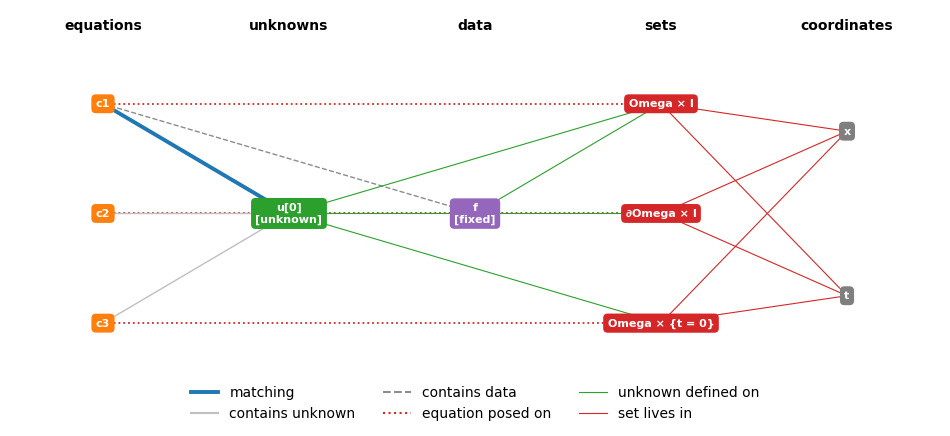

In [11]:
eq.plot_coupling(forward_task)

In [13]:
print(eq.weak_form(forward_task))

find u:
  F[v_u] = + ∫ inner(∂u/∂t, v_u) dx + ∫ inner(2·∇_x u, ∇_x v_u) dx - ∫ inner(f, v_u) dx = 0
  essential: u = 0 on ∂Omega × I
  also: u = 0 on Omega × {t = 0}
  u in H1


In [18]:
from qewton.equations.fixtures import stokes

stokes_problem = stokes()
stokes_symbols = {s.variable.name: s for s in stokes_problem.symbols()}
stokes_task = stokes_problem.task(unknown=[stokes_symbols['u'], stokes_symbols['p']])
print(eq.weak_form(stokes_task))

find p, u:
  F[v_u] = + ∫ inner(∇_x u, ∇_x v_u) dx - ∫ inner(p, ∇_x·v_u) dx - ∫ inner(f, v_u) dx - ∫ inner(dot((∇_x u)|_{∂Omega}, n_{∂Omega}), v_u) ds + ∫ inner(p|_{∂Omega}·n_{∂Omega}, v_u) ds = 0
  F[v_p] = + ∫ inner(∇_x·u, v_p) dx = 0
  u in H1
  p in L2
